# Лабораторная работа №2: разработка сверточной нейронной сети с использованием PyTorch

In [1]:
from pathlib import Path
import contextlib
import io
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(4)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Устройство:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

PyTorch: 2.14.1+cu126
Устройство: NVIDIA GeForce RTX 2060


In [2]:
DATA_DIR = Path("cifar10_data")
BATCH_SIZE = 128

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    eval_transform,
])

with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    train_dataset = datasets.CIFAR10(DATA_DIR, train=True, download=True, transform=train_transform)
    train_eval_dataset = datasets.CIFAR10(DATA_DIR, train=True, download=False, transform=eval_transform)
    test_dataset = datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=eval_transform)
classes = train_dataset.classes

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(SEED), pin_memory=device.type == "cuda",
)
train_eval_loader = DataLoader(train_eval_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

image, label = train_eval_dataset[0]
print(f"Обучающая выборка: {train_dataset.data.shape}, метки {np.shape(train_dataset.targets)}")
print(f"Тестовая выборка: {test_dataset.data.shape}, метки {np.shape(test_dataset.targets)}")
print(f"Исходное изображение: {train_dataset.data[0].shape} (H, W, C)")
print(f"Тензор изображения: {tuple(image.shape)} (C, H, W), dtype={image.dtype}")
print(f"Метка: {label}, класс: {classes[label]}, форма метки: {np.shape(label)}")
print("Классы:", ", ".join(classes))

Обучающая выборка: (50000, 32, 32, 3), метки (50000,)
Тестовая выборка: (10000, 32, 32, 3), метки (10000,)
Исходное изображение: (32, 32, 3) (H, W, C)
Тензор изображения: (3, 32, 32) (C, H, W), dtype=torch.float32
Метка: 6, класс: frog, форма метки: ()
Классы: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck


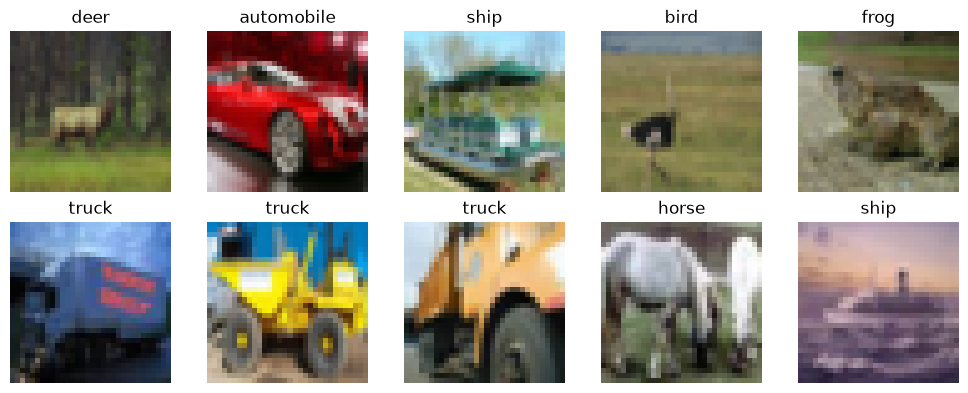

In [3]:
indices = np.random.default_rng(SEED).choice(len(train_dataset), 10, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, index in zip(axes.ravel(), indices):
    ax.imshow(train_dataset.data[index])
    ax.set_title(classes[train_dataset.targets[index]])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
class CifarCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 10),
        )

    def forward(self, X):
        features = self.features(X)
        return self.classifier(features)


model = CifarCNN().to(device)
print(model)
print("Обучаемых параметров:", sum(p.numel() for p in model.parameters() if p.requires_grad))
model.eval()
with torch.no_grad():
    output = model(image.unsqueeze(0).to(device))
assert output.shape == (1, 10)
assert torch.isfinite(output).all()
print("Форма выхода для одного изображения:", tuple(output.shape))

CifarCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

Форма выхода для одного изображения: (1, 10)


In [5]:
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
EPOCHS = 20

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.3)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum = 0.0
    correct = 0
    total = 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        logits = model(images)
        loss_sum += criterion(logits, labels).item() * len(labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += len(labels)
    return loss_sum / total, correct / total

In [6]:
history = {"loss": [], "train_loss": [], "accuracy": [], "error": [], "time": []}
training_start = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.perf_counter()
    model.train()
    loss_sum = 0.0
    examples_seen = 0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * len(labels)
        examples_seen += len(labels)

    train_loss, train_accuracy = evaluate(model, train_eval_loader)
    epoch_loss = loss_sum / examples_seen
    train_error = 1.0 - train_accuracy
    elapsed = time.perf_counter() - epoch_start
    history["loss"].append(epoch_loss)
    history["train_loss"].append(train_loss)
    history["accuracy"].append(train_accuracy)
    history["error"].append(train_error)
    history["time"].append(elapsed)
    print(f"Эпоха {epoch:2d}/{EPOCHS} | loss: {epoch_loss:.4f} | "
          f"accuracy train: {train_accuracy:.2%} | ошибка train: {train_error:.2%} | "
          f"время: {elapsed:.1f} с", flush=True)
    scheduler.step()

total_training_time = time.perf_counter() - training_start
print(f"Общее время обучения: {total_training_time:.1f} с ({total_training_time / 60:.1f} мин.)")

Эпоха  1/20 | loss: 1.5018 | accuracy train: 59.68% | ошибка train: 40.32% | время: 35.3 с


Эпоха  2/20 | loss: 1.0806 | accuracy train: 65.01% | ошибка train: 34.99% | время: 34.5 с


Эпоха  3/20 | loss: 0.9129 | accuracy train: 70.87% | ошибка train: 29.13% | время: 34.4 с


Эпоха  4/20 | loss: 0.8181 | accuracy train: 76.05% | ошибка train: 23.95% | время: 34.5 с


Эпоха  5/20 | loss: 0.7508 | accuracy train: 78.43% | ошибка train: 21.57% | время: 34.7 с


Эпоха  6/20 | loss: 0.6867 | accuracy train: 74.48% | ошибка train: 25.52% | время: 34.5 с


... (11 outputs left out)

Эпоха 18/20 | loss: 0.3604 | accuracy train: 89.96% | ошибка train: 10.04% | время: 34.7 с


Эпоха 19/20 | loss: 0.3480 | accuracy train: 90.49% | ошибка train: 9.51% | время: 34.6 с


Эпоха 20/20 | loss: 0.3422 | accuracy train: 89.53% | ошибка train: 10.47% | время: 34.5 с


Общее время обучения: 695.4 с (11.6 мин.)


In [7]:
test_loss, test_accuracy = evaluate(model, test_loader)
test_error = 1.0 - test_accuracy
print(f"Cross-entropy на тестовой выборке: {test_loss:.4f}")
print(f"Точность на тестовой выборке: {test_accuracy:.2%}")
print(f"Ошибка классификации на тестовой выборке: {test_error:.2%}")
assert np.isfinite(history["loss"]).all()
assert 0 <= test_accuracy <= 1

Cross-entropy на тестовой выборке: 0.4592
Точность на тестовой выборке: 85.01%
Ошибка классификации на тестовой выборке: 14.99%


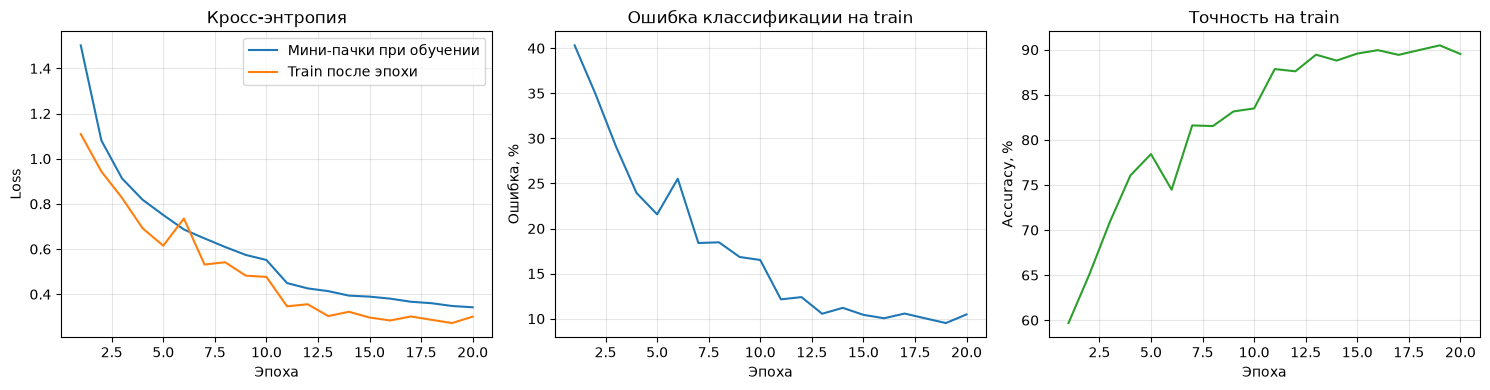

In [8]:
epochs_axis = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(epochs_axis, history["loss"], label="Мини-пачки при обучении")
axes[0].plot(epochs_axis, history["train_loss"], label="Train после эпохи")
axes[0].set(title="Кросс-энтропия", xlabel="Эпоха", ylabel="Loss")
axes[0].legend()
axes[1].plot(epochs_axis, np.array(history["error"]) * 100)
axes[1].set(title="Ошибка классификации на train", xlabel="Эпоха", ylabel="Ошибка, %")
axes[2].plot(epochs_axis, np.array(history["accuracy"]) * 100, color="tab:green")
axes[2].set(title="Точность на train", xlabel="Эпоха", ylabel="Accuracy, %")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

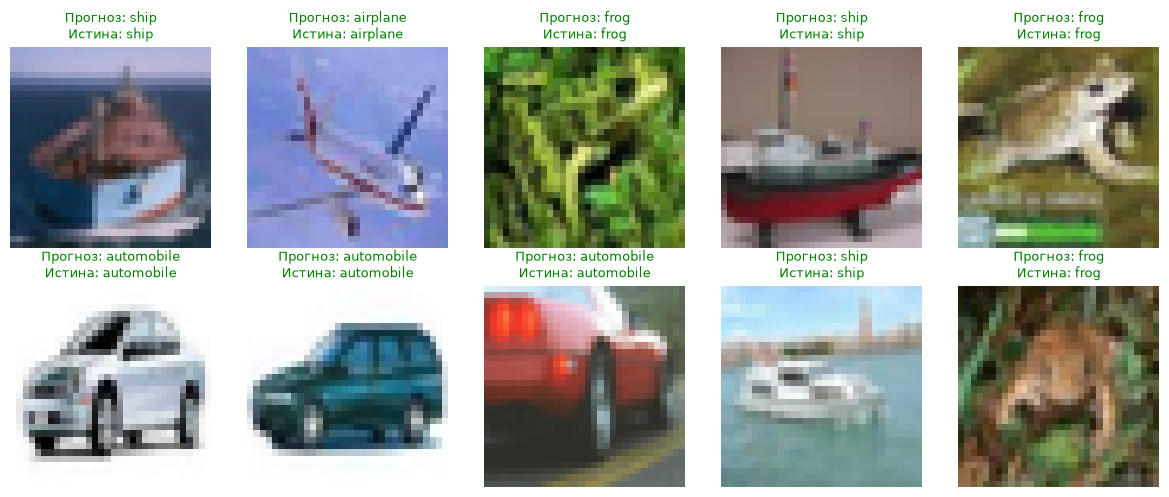

In [9]:
indices = np.random.default_rng(SEED).choice(len(test_dataset), 10, replace=False)
images = torch.stack([test_dataset[int(index)][0] for index in indices]).to(device)
model.eval()
with torch.no_grad():
    predictions = model(images).argmax(dim=1).cpu().numpy()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, index, prediction in zip(axes.ravel(), indices, predictions):
    target = test_dataset.targets[index]
    ax.imshow(test_dataset.data[index])
    ax.set_title(f"Прогноз: {classes[prediction]}\nИстина: {classes[target]}",
                 color="green" if prediction == target else "red", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()